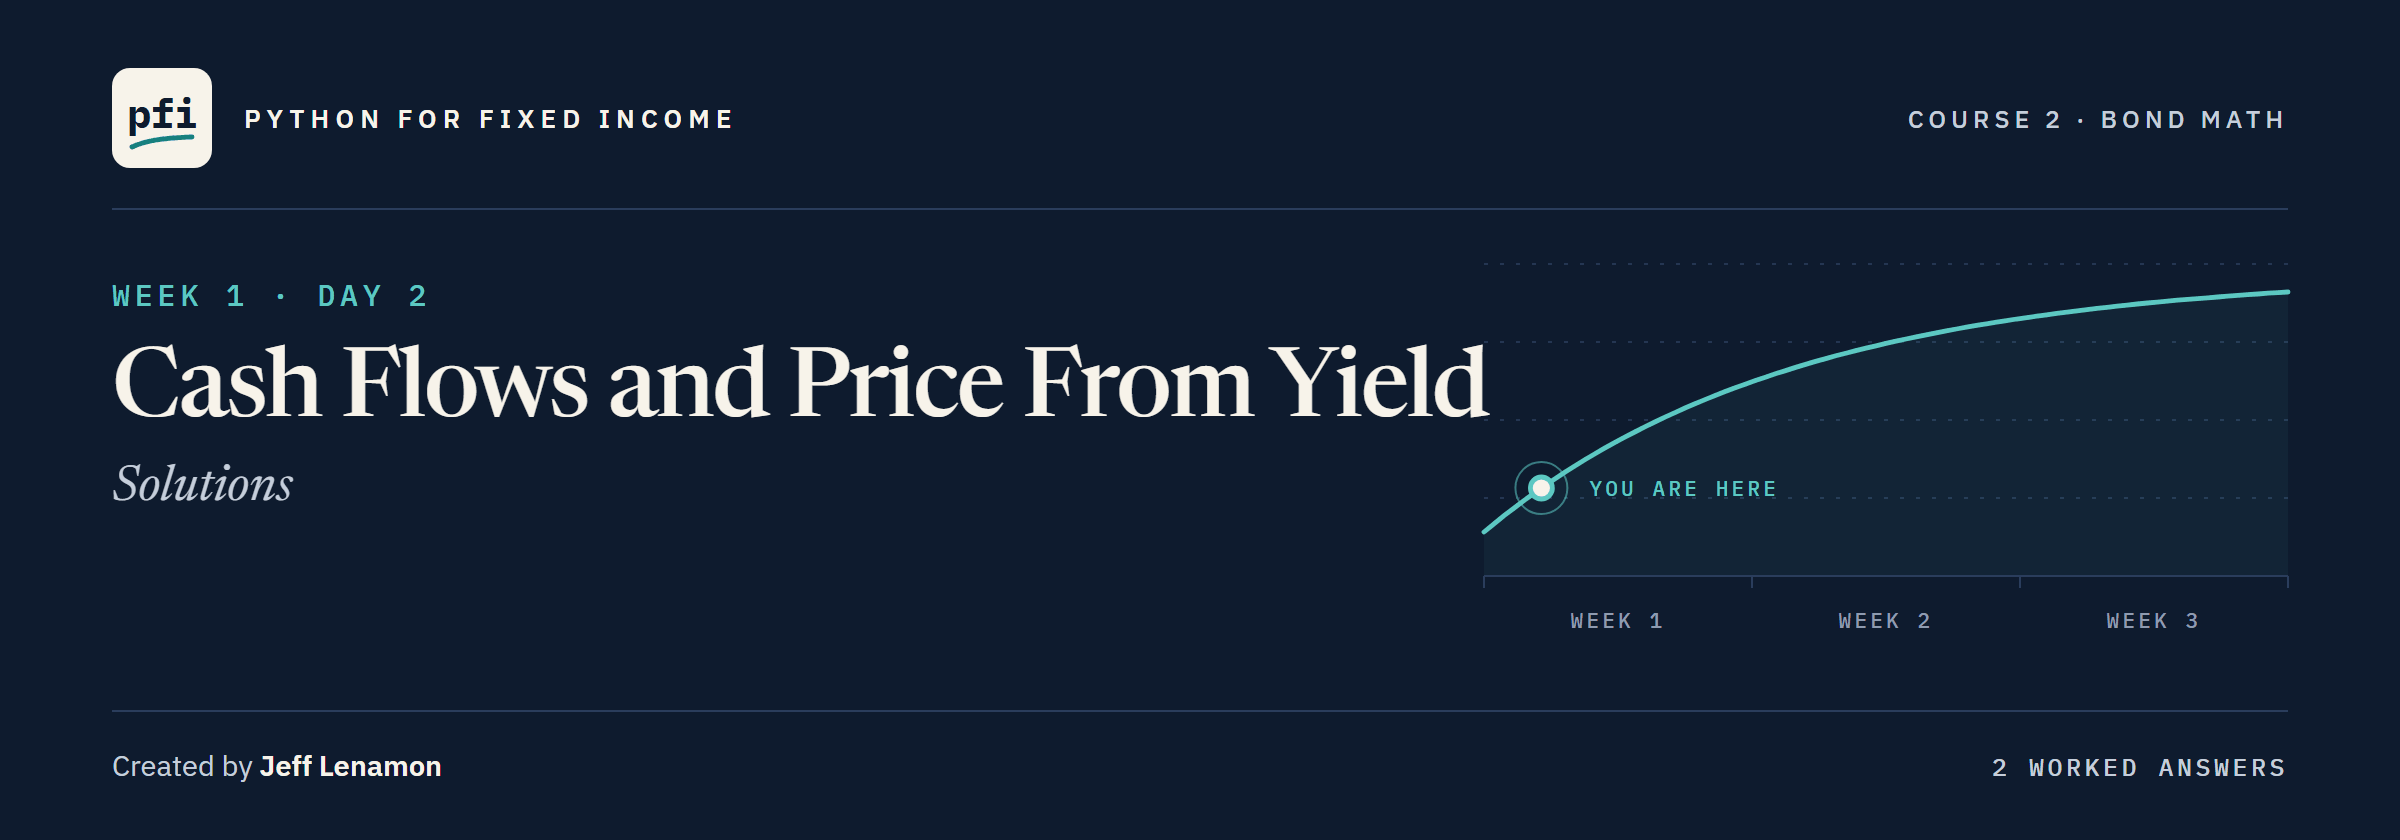

# Cash Flows and Price From Yield: Solutions

Week 1, Day 2. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day2/02_cash_flows_and_price_from_yield_solutions.ipynb)

## Exercises

Run the next three cells first: the work folder with the module as the notebook ends, the imports and the bonds, and `check`.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 02 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(2, after=2)

Work folder pfi_course2_02_k4w7q2xr: 2 data files, the module as notebook 02 left it, 2 commits


In [2]:
import importlib

import pandas as pd

import bondmath

tvm = pd.read_csv('bondmath_excel_reference_tvm.csv', index_col='case_id')
pv_bond_rows = tvm[tvm['function'] == 'PV_BOND']
exercise_bonds = pd.DataFrame({
    'issuer': ['Ostrevale Telecom', 'Tarnwick Utilities', 'Osmere Chemicals', 'Calderby Retail'],
    'ticker': ['OSTV', 'TRNW', 'OSMC', 'CLDB'],
    'coupon_pct': [5.625, 4.375, 5.0, 8.25],
    'years': [4, 2, 6, 8],
    'yield_pct': [5.8, 4.3, 5.35, 8.6],
})

In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

### Exercise 1

In [4]:
terms = zip(exercise_bonds['coupon_pct'], exercise_bonds['yield_pct'], exercise_bonds['years'])
exercise_bonds['price'] = [bondmath.price_from_yield(c, y, t) for c, y, t in terms]
ex1_osmere = exercise_bonds.loc[2, 'price']
ex1_premium = list(exercise_bonds.loc[exercise_bonds['price'] > 100, 'ticker'])
check('Exercise 1 Osmere', ex1_osmere, 98.2237648969068)
check('Exercise 1 above 100', ex1_premium, ['TRNW'])

Exercise 1 Osmere: correct
Exercise 1 above 100: correct


Tarnwick alone has a coupon, 4.375, above its yield, 4.30: 100.1423.

### Exercise 2

In [5]:
calderby = bondmath.cash_flows(8.25, 8)
ex2_payments = len(calderby)
ex2_total_cash = sum([amount for time_years, amount in calderby])
ex2_redemption_share_pct = (bondmath.present_value(100, 8.6, 8)
                            / bondmath.price_from_yield(8.25, 8.6, 8) * 100)
check('Exercise 2 payments', ex2_payments, 16)
check('Exercise 2 total cash', ex2_total_cash, 166.0)
check('Exercise 2 redemption share', ex2_redemption_share_pct, 52.023761197236674)

Exercise 2 payments: correct
Exercise 2 total cash: correct
Exercise 2 redemption share: correct


Eight years at 8.60 percent: the 100 is barely half of Calderby's price.

### Exercise 3

In [6]:
# the price is per 100 of face, so divide the face by 100
ex3_value_dollars = 5_000_000 / 100 * bondmath.price_from_yield(5.625, 5.8, 4)
check('Exercise 3 value in dollars', ex3_value_dollars, 4969158.881408045)

Exercise 3 value in dollars: correct


### Exercise 4

In [7]:
%%writefile -a bondmath.py


def annual_coupon_income_dollars(par: float, coupon_pct: float) -> float:
    """The coupon income a position earns in one year, in dollars.

    Units: par in dollars of face, coupon_pct in percent of face a year. Returns dollars.
    Convention: par x coupon_pct / 100, whatever the frequency: the frequency splits the year's
    coupon into payments and does not change the total.
    Excel: =par*coupon_pct/100
    """
    # percent of face, applied to the dollars of face held
    return par * coupon_pct / 100

Appending to bondmath.py


In [8]:
%%writefile -a test_bondmath.py


def test_annual_coupon_income_matches_cash_flows():
    # a hand case: 1,000,000 dollars of face at 5.25 percent earns 52,500 dollars a year
    result = bondmath.annual_coupon_income_dollars(1_000_000, 5.25)
    assert result == pytest.approx(52_500.0, abs=1e-6)
    # under 2 years the first year's payments include the 100, so those rows are left out
    rows = [row for row in tvm_rows("PV_BOND") if float(row["years"]) >= 2]
    assert rows, "no PV_BOND rows of 2 years or more"
    for row in rows:
        coupon_pct = float(row["coupon_pct"])
        frequency = int(row["frequency"])
        # the first year: one payment for an annual bond, two for semiannual, four for quarterly
        first_year = bondmath.cash_flows(coupon_pct, float(row["years"]), frequency)[:frequency]
        expected = sum([amount for time_years, amount in first_year]) * 1_000_000 / 100
        result = bondmath.annual_coupon_income_dollars(1_000_000, coupon_pct)
        assert result == pytest.approx(expected, abs=1e-6), row["case_id"]

Appending to test_bondmath.py


In [9]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.......                                                                  [100%]
7 passed in 0.50s



In [10]:
importlib.reload(bondmath)
ex4_value = bondmath.annual_coupon_income_dollars(5_000_000, 5.625)
check('Exercise 4 coupon income', ex4_value, 281250.0)

Exercise 4 coupon income: correct


281,250.00 dollars a year, paid as two coupons of 140,625.00: the frequency splits the total and does not change it, so the function takes no frequency.

### Exercise 5: AI check

The bug: each payment was `coupon_pct`, the full annual coupon, every period, where the docstring's frequency splits it.
Quorvane came back 122.0889, Predict 3's doubled-coupon price: the clue.
The fix: `coupon_pct / frequency`.

In [11]:
def assistant_price_from_yield(coupon_pct, yield_pct, years, frequency=2):
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    """
    periods = round(years * frequency)
    period_yield = yield_pct / 100 / frequency
    price = 0.0
    for k in range(1, periods + 1):
        # the fix: each payment is the annual coupon split into frequency parts
        coupon = coupon_pct / frequency
        amount = coupon + 100 if k == periods else coupon
        price += amount / (1 + period_yield) ** k
    return price

In [12]:
columns = zip(pv_bond_rows.index, pv_bond_rows['coupon_pct'], pv_bond_rows['rate_pct'],
              pv_bond_rows['years'], pv_bond_rows['frequency'], pv_bond_rows['excel_value'])
for case, coupon_pct, yield_pct, years, frequency, excel in columns:
    result = assistant_price_from_yield(coupon_pct, yield_pct, years, frequency)
    # rate_pct is the yield; Excel's -PV with the coupon is the price
    assert abs(result - excel) < 1e-6, f'{case}: {result:.6f} against {excel:.6f}'
print(f'All {len(pv_bond_rows)} PV_BOND rows match Excel')

All 20 PV_BOND rows match Excel


In [13]:
ex5_quorvane = assistant_price_from_yield(5.25, 5.4, 5)
ex5_rows = len(pv_bond_rows)
check('Exercise 5 Quorvane', ex5_quorvane, 99.35032727691542)
check('Exercise 5 rows checked', ex5_rows, 20)

Exercise 5 Quorvane: correct
Exercise 5 rows checked: correct


[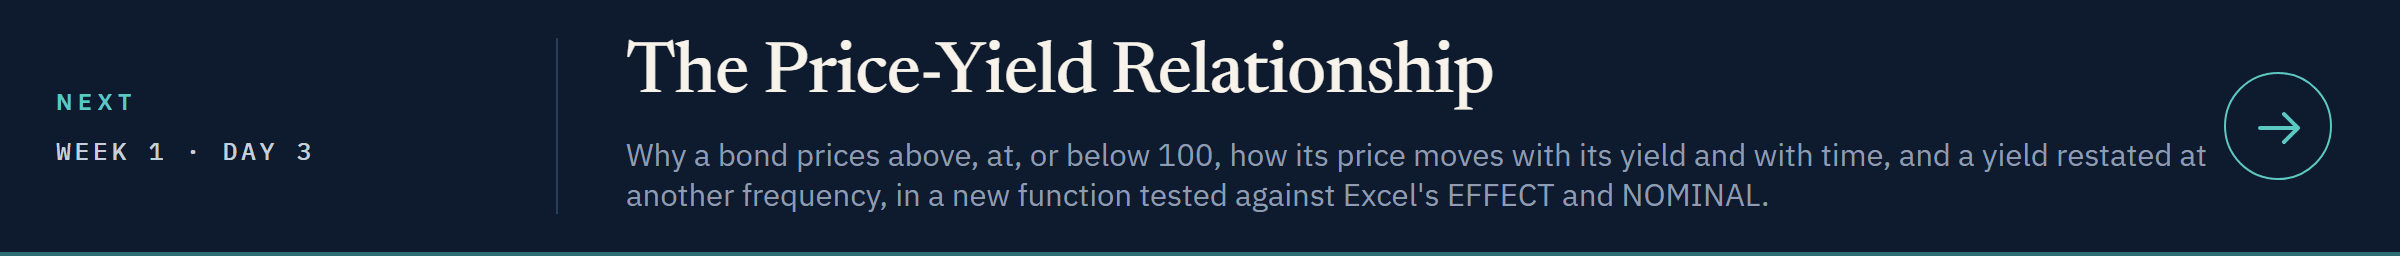](../day3/03_the_price_yield_relationship.ipynb)

[Open Day 3 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day3/03_the_price_yield_relationship.ipynb)